# 07. Бизнес-симуляция: кому выгодно давать промокод

**Цель.** Сравнить по прибыли стратегии "промокод никому", "промокод всем новым посетителям" и "промокод тем, кого выбрала модель" (при разных порогах). Понять, при каких допущениях вывод меняется, и описать, как проверить эффект в реальности.

**Что уже известно из 05-06.**
- Модель (случайный лес без `PageValues`) хорошо откалибрована: её оценку можно читать как вероятность покупки *без промокода*.
- Новые посетители покупают в 24.7% визитов, то есть чаще среднего (02-03).
- "Почти-покупатели" (модель ждала покупку, а её не было) по поведению похожи на настоящих покупателей. Модель не может отличить их от тех, кто купит (06).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

from src.business import (Assumptions, best_strategies, persuasion_probability, session_value,
                          strategy_summary, threshold_curve)
from src.config import MODELS_DIR, OOF_PATH, TARGET, TEST_PRED_PATH
from src.data import load_test, load_train
from src.plots import AQUA, BLUE, GRAY, INK_2, ORANGE, YELLOW, save_fig, setup_style

setup_style()
pd.set_option("display.precision", 3)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}".replace(",", " "))

train = load_train()
y_tr = train[TARGET].to_numpy()
p_tr = pd.read_csv(OOF_PATH, index_col="row_id")["p_oof"].reindex(train.index).to_numpy()
new_tr = (train["VisitorType"] == "New_Visitor").to_numpy()

test = load_test()
y_te = test[TARGET].to_numpy()
p_te = pd.read_csv(TEST_PRED_PATH, index_col="row_id")["p"].reindex(test.index).to_numpy()
new_te = (test["VisitorType"] == "New_Visitor").to_numpy()

with open(MODELS_DIR / "final_model_params.json", encoding="utf-8") as f:
    THRESHOLD_F1 = json.load(f)["threshold_max_f1_oof"]

# Средняя оценка модели среди не купивших (по OOF train), опорная точка для "теплоты"
P_REF = p_tr[y_tr == 0].mean()
THRESHOLDS = np.round(np.arange(0, 1.0001, 0.01), 2)
print(f"train (OOF): {len(y_tr)} сессий; test: {len(y_te)} сессий")
print(f"Средняя оценка модели среди не купивших (train): {P_REF:.3f}")

train (OOF): 9864 сессий; test: 2466 сессий
Средняя оценка модели среди не купивших (train): 0.135


## 1. Допущения

В данных нет ни сумм заказов, ни информации о том, как люди реагируют на промокоды. Поэтому всё, что касается денег, держится на допущениях. Я собрал их в одну таблицу, а в разделе 5 проверяю, как от них зависит вывод.

Как я представляю сценарий: модель оценивает сессию **во время визита**, и если стратегия говорит "да", посетитель видит промокод (например, всплывающее окно). Упрощение: модель видит поведение за всю сессию (других данных нет), так что в реальности она была бы слабее.

In [2]:
BASE = Assumptions()
assumptions_table = pd.DataFrame([
    ("Средний чек", f"{BASE.aov:,.0f} ₽".replace(",", " "),
     "Допущение: сумм заказов в данных нет. На выбор стратегии не влияет (все слагаемые пропорциональны чеку), меняет только масштаб в рублях"),
    ("Маржа", f"{BASE.margin:.0%} от чека",
     "Допущение: порядок величины для непродуктового интернет-магазина"),
    ("Скидка по промокоду", f"{BASE.discount:.0%} от чека", "Типичный размер приветственной скидки"),
    ("Каннибализация", f"{BASE.cannibalization:.0%}",
     "Доля тех, кто купил бы и так, но применит код. Беру 100%: кто собирался купить и увидел скидку, ей воспользуется"),
    ("Сила промокода", f"{BASE.persuasion:.0%} ушедших",
     "Какая доля тех, кто ушёл бы без покупки, купит благодаря промокоду (в среднем). Главный неизвестный параметр, его и должен измерить A/B-тест"),
    ("Теплота эффекта", f"{BASE.warmth}",
     "0: промокод одинаково действует на всех ушедших. 1: действует пропорционально оценке модели (на почти-покупателей сильнее, на случайных посетителей почти никак). 0.5: середина"),
], columns=["параметр", "значение", "откуда и почему"]).set_index("параметр")
assumptions_table

,значение,откуда и почему
параметр,,
Средний чек,3 000 ₽,Допущение: сумм заказов в данных нет. На выбор...
Маржа,30% от чека,Допущение: порядок величины для непродуктового...
Скидка по промокоду,10% от чека,Типичный размер приветственной скидки
Каннибализация,100%,"Доля тех, кто купил бы и так, но применит код...."
Сила промокода,5% ушедших,"Какая доля тех, кто ушёл бы без покупки, купит..."
Теплота эффекта,0.5,0: промокод одинаково действует на всех ушедши...


## 2. Как считается прибыль

Считаю **дополнительную** прибыль по сравнению со стратегией "промокод никому". Для каждой сессии, которой показали промокод:
- **если человек купил бы и так** (в данных `Revenue = 1`), магазин просто теряет скидку: 10% от 3000 ₽ = **-300 ₽**. Это *каннибализация*: скидка достаётся тому, кто заплатил бы полную цену;
- **если человек ушёл бы без покупки**, промокод с вероятностью *q* превращает его в покупателя. Тогда магазин получает маржу минус скидку: 30% - 10% = 20% от чека = **+600 ₽**, а в среднем по таким сессиям *q* × 600 ₽.

Вероятность *q* зависит от "теплоты" посетителя:

*q* = сила промокода × ((1 - теплота) + теплота × оценка модели / 0.135),

где 0.135 равно средней оценке модели среди не купивших. При теплоте 0.5 посетитель с оценкой 0.3 "дожимается" с вероятностью около 8%, а с оценкой 0.02 около 3%.

Что я беру из данных: кто купил бы без промокода (`Revenue`) и оценку модели. Всё остальное беру из таблицы допущений.

In [3]:
example = pd.DataFrame({
    "оценка модели": [0.02, 0.10, 0.30, 0.50],
})
example["q (шанс дожать, если ушёл бы)"] = persuasion_probability(example["оценка модели"], BASE, P_REF)
example["прибыль, если ушёл бы, ₽ (в среднем)"] = session_value(np.zeros(4), example["оценка модели"], BASE, P_REF)
example["прибыль, если купил бы и так, ₽"] = session_value(np.ones(4), example["оценка модели"], BASE, P_REF)
example["ожидаемая прибыль с учётом оценки, ₽"] = (
    example["оценка модели"] * example["прибыль, если купил бы и так, ₽"]
    + (1 - example["оценка модели"]) * example["прибыль, если ушёл бы, ₽ (в среднем)"])
example.set_index("оценка модели").round(3)

,"q (шанс дожать, если ушёл бы)","прибыль, если ушёл бы, ₽ (в среднем)","прибыль, если купил бы и так, ₽","ожидаемая прибыль с учётом оценки, ₽"
оценка модели,,,,
0.020,0.029,17.215,-300.000,10.871
0.100,0.043,26.075,-300.000,-6.532
0.300,0.080,48.226,-300.000,-56.242
0.500,0.117,70.376,-300.000,-114.812


**Что увидел.** Одна "каннибализированная" покупка стоит 300 ₽, а показ промокода тому, кто ушёл бы, приносит в среднем от 17 до 70 ₽ (600 ₽ × шанс "дожать"). При оценке 0.02 ожидаемая прибыль от показа ещё положительна (+10.9 ₽). Ожидаемая прибыль от показа промокода отрицательна уже при оценке 0.10 (-6.5 ₽) и становится всё хуже с ростом оценки: при 0.50 уже -115 ₽.

**Что это значит.** Чем увереннее модель, что человек купит, тем *дороже* дать ему промокод: скорее всего, он купил бы и так. Это главная особенность задачи. Модель предсказывает "кто купит", а для промокода нужно знать "кто купит **благодаря** промокоду". Это разные вопросы.

## 3. Сколько должен "дожимать" промокод, чтобы окупиться

Простой расчёт без модели "теплоты". Пусть в группе конверсия без промокода *r*, и промокод превращает в покупателей долю *q* ушедших. Промокод окупается, если

(1 - *r*) × *q* × (маржа - скидка) > *r* × каннибализация × скидка,

то есть *q* > *r* × 0.10 / ((1 - *r*) × 0.20). Считаю *r* для каждой группы по train.

In [4]:
def breakeven_q(r, a=BASE):
    return r * a.cannibalization * a.discount / ((1 - r) * (a.margin - a.discount))

groups = {
    "все посетители": np.ones_like(y_tr, dtype=bool),
    "новые посетители": new_tr,
    f"модель: оценка ≥ {THRESHOLD_F1:.3f} (почти-покупатели + покупатели)": p_tr >= THRESHOLD_F1,
    "модель: оценка ≥ 0.4": p_tr >= 0.4,
    "модель: оценка < 0.1": p_tr < 0.1,
}
be = pd.DataFrame({
    "сессий": {k: m.sum() for k, m in groups.items()},
    "конверсия без промокода r": {k: y_tr[m].mean() for k, m in groups.items()},
})
be["нужно дожать ушедших, не меньше"] = be["конверсия без промокода r"].map(breakeven_q)
be

,сессий,конверсия без промокода r,"нужно дожать ушедших, не меньше"
все посетители,9864,0.155,0.092
новые посетители,1347,0.247,0.164
модель: оценка ≥ 0.224 (почти-покупатели + покупатели),2598,0.345,0.263
модель: оценка ≥ 0.4,505,0.509,0.518
модель: оценка < 0.1,3911,0.031,0.016


**Что увидел.** Чтобы промокод **всем** окупился, он должен превращать в покупателей не меньше 9.2% ушедших. Для **новых посетителей** нужно 16.4%, потому что у них и так высокая конверсия. Для группы, которую модель отмечает при пороге 0.224 (почти-покупатели вместе с покупателями), нужно 26.3%. Для самых "уверенных" (оценка ≥ 0.4) 51.8%. Для самых "холодных" (оценка < 0.1) всего 1.6%.

**Что это значит.** Промокод тем, кого модель считает вероятными покупателями, окупится, только если он очень сильный: дожимает четверть и больше ушедших. Реалистичнее ожидать, что он сработает на единицы процентов. Отсюда предварительный вывод: **давать промокод "самым тёплым" по модели невыгодно, а модель полезнее для обратного: чтобы НЕ давать промокод тем, кто купит и так.**

## 4. Стратегии и выбор порога

Сравниваю:
1. **никому**: точка отсчёта, 0 ₽;
2. **всем новым посетителям**;
3. **всем** (для справки);
4. **по модели: "оценка ≥ t"**: промокод тем, кого модель считает вероятными покупателями (исходная идея проекта);
5. **по модели: "оценка < t"**: новая идея из раздела 3, промокод всем, *кроме* тех, кто с большой вероятностью купит и так.

Порог *t* выбираю по **OOF-предсказаниям на train**. Потом один раз проверяю выбранные стратегии на тесте. Прибыль показываю в рублях на 1000 сессий, чтобы train и test можно было сравнивать.

In [5]:
n_tr = len(y_tr)
curve_above = threshold_curve(y_tr, p_tr, BASE, P_REF, THRESHOLDS, "above") / n_tr * 1000
curve_below = threshold_curve(y_tr, p_tr, BASE, P_REF, THRESHOLDS, "below") / n_tr * 1000
value_tr = session_value(y_tr, p_tr, BASE, P_REF)
profit_new_tr = value_tr[new_tr].sum() / n_tr * 1000
profit_all_tr = value_tr.sum() / n_tr * 1000

t_above = THRESHOLDS[np.argmax(curve_above)]
t_below = THRESHOLDS[np.argmax(curve_below)]
print(f"Оценка ≥ t: лучший порог {t_above:.2f}, прибыль {curve_above.max():,.0f} ₽ на 1000 сессий; "
      f"худший порог {THRESHOLDS[np.argmin(curve_above)]:.2f}, {curve_above.min():,.0f} ₽")
print(f"Оценка < t: лучший порог {t_below:.2f}, прибыль {curve_below.max():,.0f} ₽ на 1000 сессий")
print(f"Всем новым: {profit_new_tr:,.0f} ₽; всем: {profit_all_tr:,.0f} ₽ на 1000 сессий")

# При пороге 0.224 из ноутбука 05 и при таком же числе получателей, как у "всем новым"
k_new = new_tr.sum()
t_same_volume = np.sort(p_tr)[::-1][k_new - 1]
mask_same = p_tr >= t_same_volume
print(f"\nОценка ≥ {THRESHOLD_F1:.3f} (порог из 05): "
      f"{value_tr[p_tr >= THRESHOLD_F1].sum() / n_tr * 1000:,.0f} ₽ на 1000 сессий")
print(f"Модель, столько же получателей, сколько новых посетителей ({k_new}): "
      f"конверсия в группе {y_tr[mask_same].mean():.1%} (у новых {y_tr[new_tr].mean():.1%}), "
      f"прибыль {value_tr[mask_same].sum() / n_tr * 1000:,.0f} ₽ на 1000 сессий")

Оценка ≥ t: лучший порог 0.62, прибыль 0 ₽ на 1000 сессий; худший порог 0.11, -24,839 ₽
Оценка < t: лучший порог 0.11, прибыль 3,786 ₽ на 1000 сессий
Всем новым: -6,122 ₽; всем: -21,052 ₽ на 1000 сессий

Оценка ≥ 0.224 (порог из 05): -18,710 ₽ на 1000 сессий
Модель, столько же получателей, сколько новых посетителей (1347): конверсия в группе 41.6% (у новых 24.7%), прибыль -12,515 ₽ на 1000 сессий


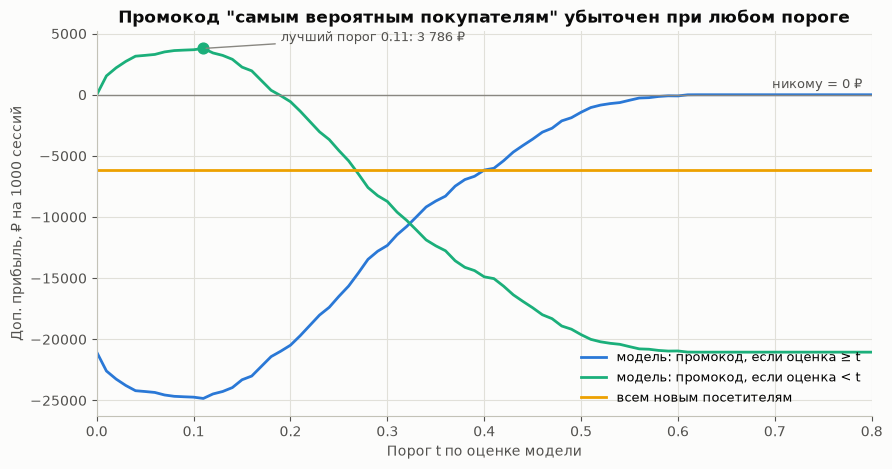

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(THRESHOLDS, curve_above, color=BLUE, label="модель: промокод, если оценка ≥ t")
ax.plot(THRESHOLDS, curve_below, color=AQUA, label="модель: промокод, если оценка < t")
ax.axhline(profit_new_tr, color=YELLOW, linewidth=2, label="всем новым посетителям")
ax.axhline(0, color=GRAY, linewidth=1)
ax.text(0.79, 300, "никому = 0 ₽", ha="right", va="bottom", color=INK_2, fontsize=9)
ax.scatter([t_below], [curve_below.max()], s=60, color=AQUA, zorder=3)
ax.annotate(f"лучший порог {t_below:.2f}: {curve_below.max():,.0f} ₽".replace(",", " "),
            (t_below, curve_below.max()), xytext=(t_below + 0.08, curve_below.max() + 600),
            color=INK_2, fontsize=9, arrowprops={"arrowstyle": "-", "color": GRAY})
ax.set_xlim(0, 0.8)
ax.set_xlabel("Порог t по оценке модели")
ax.set_ylabel("Доп. прибыль, ₽ на 1000 сессий")
ax.set_title('Промокод "самым вероятным покупателям" убыточен при любом пороге')
ax.legend(loc="lower right", fontsize=9)
save_fig(fig, "07_profit_vs_threshold")
plt.show()

**Что увидел.**

- **"Оценка ≥ t" убыточна при любом пороге.** Если опускать порог от 0.6 вниз (промокод получает всё больше людей), убыток растёт. Максимальный убыток -24 839 ₽ на 1000 сессий при t = 0.11, то есть хуже, чем "всем" (-21 052 ₽): из промо выпадают только самые "холодные", на которых промокод хоть немного зарабатывал. Лучший порог в этой стратегии 0.62, при котором промокод не получает никто. При пороге 0.224 из ноутбука 05 убыток -18 710 ₽ на 1000 сессий.
- **"Всем новым":** -6 122 ₽ на 1000 сессий. Если дать промокод по модели такому же числу людей (1347), конверсия в выбранной группе будет 41.6% против 24.7% у новых, а убыток -12 515 ₽, то есть вдвое больше.
- **"Оценка < t"** при пороге 0.11 даёт небольшой плюс: +3 786 ₽ на 1000 сессий.

**Что это значит.** Исходная идея проекта, "промокод тем, кого выбрала модель", при базовых допущениях проигрывает даже "всем новым". Модель хорошо находит тех, кто купит и так, и именно им отдаёт скидку.

Модель полезна в обратную сторону: чтобы *исключить* из промо тех, кто купит без него. Но выигрыш от "оценка < t" небольшой и держится на допущении, что промокод действует и на "холодных" посетителей (при теплоте 0.5 они "дожимаются" с вероятностью около 3%). Порог 0.11 означает, что промокод получат около 40% визитов с самыми низкими оценками. Это в основном короткие визиты, и неизвестно, успеет ли человек вообще увидеть предложение.

### Проверка на тесте

Пороги зафиксированы по train: для "оценка ≥ t" это 0.62 (фактически никому), для "оценка < t" это 0.11. Считаю все стратегии на тесте один раз. Отдельной строкой идут "почти-покупатели" по порогу 0.224 из ноутбука 05.

In [7]:
test_strategies = pd.DataFrame([
    strategy_summary("никому", np.zeros_like(y_te, dtype=bool), y_te, p_te, BASE, P_REF),
    strategy_summary("всем новым", new_te, y_te, p_te, BASE, P_REF),
    strategy_summary("всем", np.ones_like(y_te, dtype=bool), y_te, p_te, BASE, P_REF),
    strategy_summary(f"модель: оценка ≥ {THRESHOLD_F1:.3f} (порог из 05)", p_te >= THRESHOLD_F1, y_te, p_te, BASE, P_REF),
    strategy_summary(f"модель: оценка ≥ {t_above:.2f} (лучший по train)", p_te >= t_above, y_te, p_te, BASE, P_REF),
    strategy_summary(f"модель: оценка < {t_below:.2f} (лучший по train)", p_te < t_below, y_te, p_te, BASE, P_REF),
]).set_index("стратегия")
test_strategies

,получили промокод,доля сессий,из них купили бы и так,ожидаемо дожато покупок,"прибыль, ₽","прибыль на 1000 сессий, ₽"
стратегия,,,,,,
никому,0,0.000,0,0.000,0.000,0.000
всем новым,347,0.141,89,16.893,-16 564.472,-6 717.142
всем,2466,1.000,382,105.368,-51 379.443,-20 835.135
модель: оценка ≥ 0.224 (порог из 05),641,0.260,205,36.283,-39 730.214,-16 111.198
модель: оценка ≥ 0.62 (лучший по train),0,0.000,0,0.000,0.000,0.000
модель: оценка < 0.11 (лучший по train),1034,0.419,42,32.962,7 176.986,2 910.375


**Что увидел.** Картина на тесте та же:
- "всем новым": -6 717 ₽ на 1000 сессий, промокод получили 347 человек, 89 из них купили бы и так;
- "всем": -20 835 ₽;
- сегмент по порогу 0.224: -16 111 ₽, 641 промокод, из них 205 тем, кто купил бы и так, ожидаемо "дожато" 36 покупок;
- "оценка < 0.11": +2 910 ₽ на 1000 сессий, 1034 промокода, 42 "каннибализированных", ожидаемо "дожато" 33 покупки. На 2466 тестовых сессиях это +7 177 ₽.

**Что это значит.** Выбор, сделанный на train, на тесте подтверждается: убыточные стратегии убыточны и здесь, и в том же порядке. Но выигрыш лучшей стратегии около 3 ₽ на визит, а это меньше, чем неопределённость в допущениях. Поэтому это не вывод "надо внедрять", а вывод "стоит проверить экспериментом".

## 5. Анализ чувствительности

Все цифры выше держатся на допущениях. Проверяю, как меняется вывод, если допущения другие. Для каждого набора допущений заново выбираю лучший порог по train (OOF) и сравниваю стратегии в рублях на 1000 сессий.

### 5.1. По одному параметру

In [8]:
def winner(row, tol=100):
    """Победитель с допуском: сложная стратегия должна обгонять простую хотя бы на 100 ₽ / 1000 сессий."""
    order = ["никому", "всем", "всем новым", "модель: оценка ≥ t", "модель: оценка < t"]
    best = row[order].max()
    for name in order:
        if row[name] >= best - tol:
            return name

variations = {
    "aov": [1500, 3000, 6000],
    "margin": [0.20, 0.30, 0.40, 0.50],
    "discount": [0.05, 0.10, 0.15, 0.20],
    "cannibalization": [0.5, 0.75, 1.0],
    "persuasion": [0.02, 0.05, 0.10, 0.15, 0.20],
    "warmth": [0.0, 0.5, 1.0],
}
param_ru = {"aov": "средний чек", "margin": "маржа", "discount": "скидка",
            "cannibalization": "каннибализация", "persuasion": "сила промокода", "warmth": "теплота"}
rows = []
for param, values in variations.items():
    for v in values:
        a = BASE.with_(**{param: v})
        res = best_strategies(y_tr, p_tr, new_tr, a, P_REF, THRESHOLDS)
        rows.append({"параметр": param_ru[param], "значение": v, **res.round(0).to_dict(),
                     "лучшая": winner(res)})
oat = pd.DataFrame(rows).set_index(["параметр", "значение"])
oat

никому  всем новым        всем  модель: оценка ≥ t  \
параметр       значение                                                        
средний чек    1 500.000   0.000  -3 061.000 -10 526.000               0.000   
               3 000.000   0.000  -6 122.000 -21 052.000               0.000   
               6 000.000   0.000 -12 245.000 -42 105.000               0.000   
маржа          0.200       0.000  -8 125.000 -33 732.000               0.000   
               0.300       0.000  -6 122.000 -21 052.000               0.000   
               0.400       0.000  -4 120.000  -8 373.000               7.000   
               0.500       0.000  -2 117.000   4 307.000           4 307.000   
скидка         0.050       0.000     -57.000   8 493.000           8 493.000   
               0.100       0.000  -6 122.000 -21 052.000               0.000   
               0.150       0.000 -12 188.000 -50 598.000               0.000   
               0.200       0.000 -18 253.000 -80 143.000               0.000   
каннибализация 0.500       0.000  -1 059.000   2 153.000           2 153.000   
               0.750       0.000  -3 590.000  -9 450.000               2.000   
               1.000       0.000  -6 122.000 -21 052.000               0.000   
сила промокода 0.020       0.000  -8 526.000 -36 268.000               0.000   
               0.050       0.000  -6 122.000 -21 052.000               0.000   
               0.100       0.000  -2 117.000   4 307.000           4 307.000   
               0.150       0.000   1 888.000  29 665.000          29 665.000   
               0.200       0.000   5 894.000  55 024.000          55 024.000   
теплота        0.000       0.000  -7 044.000 -21 052.000               0.000   
               0.500       0.000  -6 122.000 -21 052.000               0.000   
               1.000       0.000  -5 201.000 -21 052.000              11.000   

                          модель: оценка < t              лучшая  
параметр       значение                                           
средний чек    1 500.000           1 893.000  модель: оценка < t  
               3 000.000           3 786.000  модель: оценка < t  
               6 000.000           7 573.000  модель: оценка < t  
маржа          0.200               1 379.000  модель: оценка < t  
               0.300               3 786.000  модель: оценка < t  
               0.400               8 072.000  модель: оценка < t  
               0.500              14 522.000  модель: оценка < t  
скидка         0.050              11 630.000  модель: оценка < t  
               0.100               3 786.000  модель: оценка < t  
               0.150               2 068.000  модель: оценка < t  
               0.200                 983.000  модель: оценка < t  
каннибализация 0.500               7 261.000  модель: оценка < t  
               0.750               4 866.000  модель: оценка < t  
               1.000               3 786.000  модель: оценка < t  
сила промокода 0.020               1 024.000  модель: оценка < t  
               0.050               3 786.000  модель: оценка < t  
               0.100              14 522.000  модель: оценка < t  
               0.150              33 513.000  модель: оценка < t  
               0.200              56 723.000  модель: оценка < t  
теплота        0.000               7 971.000  модель: оценка < t  
               0.500               3 786.000  модель: оценка < t  
               1.000                 272.000  модель: оценка < t

**Что увидел.**

- При базовых допущениях "оценка ≥ t" не бывает лучше "никому", а "всем новым" убыточна.
- Знак меняется только при сильных изменениях. "Всем" и "оценка ≥ t" (с порогом 0, то есть тоже "всем") становятся прибыльными при силе промокода от 10%, марже 50%, скидке 5% или каннибализации 50%.
- "Всем новым" выходит в плюс только при силе промокода от 15%.
- Средний чек, как и ожидалось, меняет только масштаб: при 1500 ₽ и 6000 ₽ прибыль ровно вдвое меньше и больше, лучшая стратегия та же.
- Во всех строках лучший вариант "оценка < t".

**Что это значит.** Направление выводов устойчиво: ни при одном изменённом параметре "промокод вероятным покупателям" не обходит остальные стратегии, а исключение уверенных покупателей никогда не хуже, чем "всем". Сильнее всего на результат влияют сила промокода и размер скидки: от них зависит, выгоден ли промокод вообще.

### 5.2. Сила промокода × "теплота": карта лучшей стратегии

Два самых неизвестных параметра меняю одновременно: силу промокода от 1% до 30% и "теплоту" от 0 до 1. Остальное как в базовых допущениях.

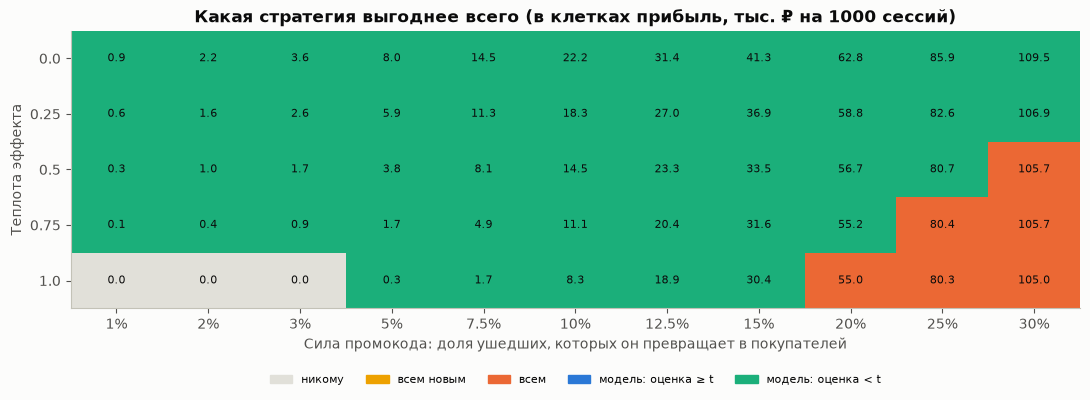

сила промокода,1.0%,2.0%,3.0%,5.0%,7.5%,10.0%,12.5%,15.0%,20.0%,25.0%,30.0%
теплота,,,,,,,,,,,
0.000,модель: оценка < t,модель: оценка < t,модель: оценка < t,модель: оценка < t,модель: оценка < t,модель: оценка < t,модель: оценка < t,модель: оценка < t,модель: оценка < t,модель: оценка < t,модель: оценка < t
0.250,модель: оценка < t,модель: оценка < t,модель: оценка < t,модель: оценка < t,модель: оценка < t,модель: оценка < t,модель: оценка < t,модель: оценка < t,модель: оценка < t,модель: оценка < t,модель: оценка < t
0.500,модель: оценка < t,модель: оценка < t,модель: оценка < t,модель: оценка < t,модель: оценка < t,модель: оценка < t,модель: оценка < t,модель: оценка < t,модель: оценка < t,модель: оценка < t,всем
0.750,модель: оценка < t,модель: оценка < t,модель: оценка < t,модель: оценка < t,модель: оценка < t,модель: оценка < t,модель: оценка < t,модель: оценка < t,модель: оценка < t,всем,всем
1.000,никому,никому,никому,модель: оценка < t,модель: оценка < t,модель: оценка < t,модель: оценка < t,модель: оценка < t,всем,всем,всем


In [9]:
persuasion_grid = np.array([0.01, 0.02, 0.03, 0.05, 0.075, 0.10, 0.125, 0.15, 0.20, 0.25, 0.30])
warmth_grid = np.array([0.0, 0.25, 0.5, 0.75, 1.0])
strategy_names = ["никому", "всем новым", "всем", "модель: оценка ≥ t", "модель: оценка < t"]
win = np.empty((len(warmth_grid), len(persuasion_grid)), dtype=object)
best_val = np.zeros(win.shape)
for i, w in enumerate(warmth_grid):
    for j, x in enumerate(persuasion_grid):
        res = best_strategies(y_tr, p_tr, new_tr, BASE.with_(persuasion=x, warmth=w), P_REF, THRESHOLDS)
        win[i, j] = winner(res)
        best_val[i, j] = res.max()

colors = {"никому": "#e1e0d9", "всем новым": YELLOW, "всем": ORANGE,
          "модель: оценка ≥ t": BLUE, "модель: оценка < t": AQUA}
codes = np.vectorize(strategy_names.index)(win)
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.imshow(codes, cmap=ListedColormap([colors[s] for s in strategy_names]), vmin=0,
          vmax=len(strategy_names) - 1, aspect="auto")
for i in range(len(warmth_grid)):
    for j in range(len(persuasion_grid)):
        ax.text(j, i, f"{best_val[i, j] / 1000:.1f}",
                ha="center", va="center", fontsize=8, color="#0b0b0b")
ax.set_xticks(range(len(persuasion_grid)))
ax.set_xticklabels([f"{x:.1%}".replace(".0%", "%") for x in persuasion_grid])
ax.set_yticks(range(len(warmth_grid)))
ax.set_yticklabels(warmth_grid)
ax.set_xlabel("Сила промокода: доля ушедших, которых он превращает в покупателей")
ax.set_ylabel("Теплота эффекта")
ax.grid(False)
handles = [plt.Rectangle((0, 0), 1, 1, color=colors[s]) for s in strategy_names]
ax.legend(handles, strategy_names, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=5, fontsize=8)
ax.set_title("Какая стратегия выгоднее всего (в клетках прибыль, тыс. ₽ на 1000 сессий)")
fig.tight_layout()
save_fig(fig, "07_sensitivity_map")
plt.show()

pd.DataFrame(win, index=pd.Index(warmth_grid, name="теплота"),
             columns=pd.Index([f"{x:.1%}" for x in persuasion_grid], name="сила промокода"))

**Что увидел.** На всей карте "оценка ≥ t" и "всем новым" ни разу не побеждают. Почти везде лучшая стратегия "оценка < t". При высокой силе промокода (20-30%) и высокой "теплоте" побеждает "всем": промокод окупается даже с учётом покупателей. Если промокод действует только на "тёплых" (теплота 1) и слабо (1-3%), лучше не давать его никому.

**Что это значит.** От допущений зависит только одно: давать ли промокод вообще и насколько широко. Кому его *не* давать (уверенным покупателям), понятно при любых допущениях. А вот ответа на вопрос "давать ли вообще" в данных нет, его даст эксперимент.

### 5.3. Когда вывод меняется на противоположный

In [10]:
fine_grid = np.round(np.arange(0.005, 0.4001, 0.005), 3)

def profit_per_1000(a, strategy):
    value = session_value(y_tr, p_tr, a, P_REF)
    if strategy == "всем новым":
        total = value[new_tr].sum()
    elif strategy == "модель: оценка ≥ t, t ≥ 0.2":
        # только "настоящие" пороги: промокод получает тёплая часть трафика, а не почти все
        total = max(value[p_tr >= t].sum() for t in THRESHOLDS if t >= 0.2)
    elif strategy == "модель: оценка < t":
        total = max(value[p_tr < t].sum() for t in THRESHOLDS)
    return total / n_tr * 1000

def min_persuasion(strategy, warmth, min_profit=100):
    """Минимальная сила промокода, при которой стратегия приносит больше 100 ₽ на 1000 сессий."""
    for x in fine_grid:
        if profit_per_1000(BASE.with_(persuasion=x, warmth=warmth), strategy) > min_profit:
            return x
    return np.nan

flip = pd.DataFrame({
    strategy: {w: min_persuasion(strategy, w) for w in [0.0, 0.5, 1.0]}
    for strategy in ["всем новым", "модель: оценка ≥ t, t ≥ 0.2", "модель: оценка < t"]
}).rename_axis("теплота")
print('Минимальная сила промокода, при которой стратегия выгоднее, чем "никому":')
flip.map(lambda v: f"{v:.1%}" if pd.notna(v) else "> 40%")

Минимальная сила промокода, при которой стратегия выгоднее, чем "никому":


,всем новым,"модель: оценка ≥ t, t ≥ 0.2",модель: оценка < t
теплота,,,
0.000,17.0%,24.0%,0.5%
0.500,13.0%,15.5%,0.5%
1.000,10.5%,11.5%,4.0%


In [11]:
# Та же граница для "тёплых" по модели при другой скидке (теплота 0.5)
disc_flip = pd.Series({
    f"скидка {d:.0%}": next((x for x in fine_grid
                             if profit_per_1000(BASE.with_(persuasion=x, discount=d), "модель: оценка ≥ t, t ≥ 0.2") > 100),
                            np.nan)
    for d in [0.05, 0.10, 0.15]
}, name='минимальная сила промокода для "модель ≥ t, t ≥ 0.2"')
disc_flip.map(lambda v: f"{v:.1%}" if pd.notna(v) else "> 40%").to_frame()

,"минимальная сила промокода для ""модель ≥ t, t ≥ 0.2"""
скидка 5%,6.5%
скидка 10%,15.5%
скидка 15%,30.5%


**Что увидел.**
- Чтобы "всем новым" стало выгоднее "никому", промокод должен "дожимать" не меньше 10.5-17% ушедших, в зависимости от теплоты.
- Для промокода "тёплым" по модели (порог не ниже 0.2) нужно больше: 11.5-24%.
- При скидке 5% вместо 10% планка для "тёплых" снижается до 6.5%, при скидке 15% растёт до 30.5% (теплота 0.5).
- "Оценка < t" выходит в плюс почти при любой силе промокода (от 0.5%), если он действует и на "холодных", и от 4%, если только на "тёплых".

**Что это значит.** Вывод "промокод по модели невыгоден" меняется на противоположный, если промокод "дожимает" больше 15.5% ушедших при скидке 10% или больше 6.5% при скидке 5%. Много это или мало, по этим данным сказать нельзя. Поэтому следующий шаг не внедрение, а эксперимент.

## 6. Как проверить эффект в реальности: A/B-тест

Главная неизвестная во всех расчётах: **сила промокода** и то, на кого он действует (*uplift*, то есть прирост вероятности покупки *благодаря* промокоду). Из исторических данных её не узнать: в них никому не давали промокод. Её может измерить только эксперимент.

**Дизайн.**
- **Кого включаем:** все визиты. Для каждого модель считает оценку, но промокод показывается по жребию.
- **Разбиение:** случайно 50/50 на "промокод" и "контроль". Единица разбиения: **посетитель** (cookie или ID), а не сессия, чтобы один человек не видел то промокод, то нет. Жребий делаю отдельно внутри групп по оценке модели (*стратификация*): "холодные" (< 0.1), "средние" (0.1-0.224), "тёплые" (≥ 0.224). Так можно измерить эффект в каждой группе и узнать, где промокод окупается.
- **Главная метрика:** дополнительная прибыль на посетителя (маржа заказов минус скидки). **Вспомогательная:** конверсия. **Контрольные метрики** (не должны ухудшиться): средний чек, доля заказов с промокодом, возвраты.
- **Длительность:** не меньше двух полных недель (чтобы покрыть будни и выходные). Результат смотрю один раз в заранее назначенную дату, не останавливаю тест при первом "значимом" результате. Если тест попадёт на ноябрь, учитываю, что поведение в сезон распродаж другое.
- **Проверки качества:** доли групп действительно 50/50 (иначе сломан жребий), до промокода группы не различаются по оценке модели.

**Размер выборки.** Считаю для конверсии (для прибыли расчёт сложнее, а порядок величины тот же) при уровне значимости 5% и мощности 80%. *Мощность* означает вероятность заметить эффект, если он на самом деле есть. *MDE* (минимальный детектируемый эффект) означает самый маленький прирост, который тест должен надёжно заметить. Беру два варианта MDE:
1. **точка безубыточности**: прирост, при котором промокод начинает окупаться (раздел 3). Меньший эффект всё равно означает "не выгодно", так что для решения "да/нет" точнее мерить не нужно;
2. **+1 п.п.**, чтобы оценить эффект точнее, например для будущей uplift-модели.

In [12]:
power = NormalIndPower()

def n_per_group(base_rate, uplift_pp):
    effect = proportion_effectsize(base_rate + uplift_pp, base_rate)
    return int(np.ceil(power.solve_power(effect_size=effect, alpha=0.05, power=0.8, ratio=1)))

ab_rows = []
for name, mask in [("все посетители", np.ones_like(y_tr, dtype=bool)),
                   ("холодные (< 0.1)", p_tr < 0.1),
                   (f"тёплые (≥ {THRESHOLD_F1:.3f})", p_tr >= THRESHOLD_F1)]:
    r = y_tr[mask].mean()
    be_uplift = (1 - r) * breakeven_q(r)  # прирост конверсии в точке безубыточности
    ab_rows.append({
        "группа": name, "доля трафика": mask.mean(), "конверсия без промокода": r,
        "MDE = безубыточность, п.п.": 100 * be_uplift,
        "n на группу (безубыточность)": n_per_group(r, be_uplift),
        "n на группу (MDE +1 п.п.)": n_per_group(r, 0.01),
    })
ab = pd.DataFrame(ab_rows).set_index("группа")
ab["всего визитов для страты (+1 п.п.)"] = (2 * ab["n на группу (MDE +1 п.п.)"] / ab["доля трафика"]).round(-3)
ab

,доля трафика,конверсия без промокода,"MDE = безубыточность, п.п.",n на группу (безубыточность),n на группу (MDE +1 п.п.),всего визитов для страты (+1 п.п.)
группа,,,,,,
все посетители,1.000,0.155,7.735,406,21062,42 000.000
холодные (< 0.1),0.396,0.031,1.572,2374,5488,28 000.000
тёплые (≥ 0.224),0.263,0.345,17.244,129,35705,271 000.000


**Что увидел.**
- **Для решения "окупается ли промокод" хватает небольших выборок.** В "тёплой" группе точка безубыточности соответствует приросту конверсии на 17.2 п.п., для его проверки нужно 129 посетителей на группу. Для всех посетителей это 7.7 п.п. и 406 на группу, для "холодных" 1.6 п.п. и 2374 на группу.
- **Чтобы измерить эффект с точностью до 1 п.п., нужно намного больше:** 21 062 на группу для всех посетителей, 5488 для "холодных", 35 705 для "тёплых" (при их конверсии 34.5% разброс больше).
- "Тёплые" составляют 26% трафика. Чтобы набрать такую выборку в этой группе, нужно около 271 тысячи визитов.

**Что это значит.** Ответить на вопрос "окупается ли промокод" можно быстро и дёшево. А измерить эффект с точностью до 1 п.п., например чтобы потом строить uplift-модель, потребуются уже месяцы трафика. Сколько это в днях, по датасету сказать нельзя: 12 330 сессий за год это выборка, а не весь трафик магазина.

## Итоги

- **Промокод "самым вероятным покупателям" убыточен** при базовых допущениях при любом пороге. При пороге 0.224 на тесте -16 111 ₽ на 1000 сессий: треть получателей купила бы и так.
- **"Всем новым" тоже убыточно:** -6 717 ₽ на 1000 сессий на тесте. Новые и так покупают в 24.7% визитов, и промокод окупится, только если "дожимает" от 13% ушедших (при теплоте 0.5).
- **Модель полезна наоборот:** чтобы исключить из промо уверенных покупателей. "Оценка < 0.11" оказалась единственной стратегией в плюсе: +2 910 ₽ на 1000 сессий на тесте. Но выигрыш маленький и держится на допущении, что промокод действует на "холодных".
- **Чувствительность:** вывод про "тёплых" меняется, если промокод "дожимает" больше 15.5% ушедших (скидка 10%) или больше 6.5% (скидка 5%). Средний чек на выбор стратегии не влияет.
- **A/B-тест:** чтобы проверить окупаемость, хватит от 129 до 2374 посетителей на группу (в зависимости от страты). Чтобы измерить эффект с точностью ±1 п.п., нужно от 5.5 до 36 тысяч на группу.

## Что не получилось или удивило

- Я ожидал, что "промокод по модели" обыграет "всем новым", а вышло наоборот. При том же числе получателей модель выбирает людей с конверсией 41.6% вместо 24.7%, и убыток вдвое больше. Хорошая модель вероятности покупки оказалась плохим инструментом для раздачи скидок.
- Самым устойчивым оказался "отрицательный" вывод (кому НЕ давать промокод), а не "положительный".
- Почти весь результат симуляции определяется двумя параметрами, которых нет в данных: силой промокода и тем, на кого он действует.

## Новые идеи

- **Uplift-модель.** После A/B-теста можно обучить модель, которая предсказывает не "купит ли", а "насколько промокод увеличит шанс покупки". Именно она нужна для таргетинга скидок.
- **Дешёвые действия вместо скидки.** Для "почти-покупателей" напоминание или бесплатная доставка от порога может окупаться там, где 10% скидки не окупаются: у них меньше потери на каннибализации.

## Следующие шаги

- Собрать выводы в README и перечислить, какие ожидания подтвердились, а какие нет.
- **При большем времени:** симуляция с размером скидки, зависящим от оценки модели; учёт повторных визитов (кто не купил сегодня, может купить завтра без скидки).